# Learned drum decoration for group fitness music

*Generative AI for Music, University of Amsterdam.*

**Group 3**: Giacomo Grazia, Sönke Erdmann and Arshana Ramautar

---

This notebook explains the project, plays the generated drums and shows the results. All code lives in `src/`;
the notebook only imports it. Heavy results (trained models, the 30 loops per system, the result tables and
figures) were produced by `python -m src.train` and `python -m src.evaluate` and are loaded from `output/`, so the
notebook runs top to bottom in seconds without a GPU. The dataset (3 MB) downloads automatically on first run.

# 0. Imports

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, Image, Markdown, display
from scipy.signal import resample_poly

from src.config import CHECKPOINT_DIR, CLASSES, DECORATION_CHANNELS, LISTEN_SEEDS, OUTPUT_DIR, SEEDS, skeleton_loop
from src.data import load_bars
from src.generate import add_fill, lstm_loop, rule_loop, rule_probabilities
from src.metrics import density
from src.plot_style import apply_style, decorate
from src.plots import plot_grid

apply_style()
RESULTS, AUDIO = OUTPUT_DIR / "results", OUTPUT_DIR / "audio"
LOOPS = dict(np.load(RESULTS / "loops.npz"))  # system -> (30 loops, 128 steps, 9 drums); B-D per training seed


def play(name: str, label: str = "", folder=AUDIO) -> None:
    """Show a label and an audio player for <folder>/<name>.wav (clips: 15 s, 8 bars at 128 BPM).

    Embedded at half the sample rate (22.05 kHz) to keep the notebook small; the full-quality WAVs are in output/audio.
    """
    if label:
        display(Markdown(f"**{label}**"))
    audio, sr = sf.read(folder / f"{name}.wav")
    display(Audio(resample_poly(audio, 1, 2), rate=sr // 2))


def show_loop(loop: np.ndarray, title: str, subtitle: str = "") -> None:
    """Draw one 8-bar loop (128, 9) as a drum grid."""
    fig, ax = plt.subplots(figsize=(14, 3.4))
    plot_grid(loop, ax=ax)
    decorate(fig, title, subtitle=subtitle)
    plt.show()

# 1. The idea

**Aesthetic goal: steady for the body, alive for the ear.** Workout drums whose pulse never wavers, so a class can
move as one, but whose groove keeps shifting like a human drummer playing for the room, rather than one bar looping
like a drum machine.

Group fitness needs both halves. *Steady*: an instructor cues moves on the beat, and a class of thirty people only
moves together if the kick lands on every beat and the snare on 2 and 4, without exception. *Alive*: a class lasts an
hour, and a single bar looped for an hour is tiring to listen to. Human drummers solve this by repeating a groove
and varying it in small ways, more at the end of a phrase.

We split the drums into two parts:

- the **skeleton**: kick on every beat ("four on the floor") and snare on beats 2 and 4. This must be reliable.
- the **decoration**: hi-hats, toms, crash and ride. This is where variation lives.

**Research question:** with kick and snare fixed, does a model trained on human drumming produce more varied drums
than hand-written rules? It has two parts:

| Part | Comparison | "Yes" means |
|---|---|---|
| **Steady:** do we need the constraint to keep the pulse? | free model B vs constrained model C | B's exact-bar rate is clearly below 100% |
| **Alive:** is the constrained model more varied than rules? | rules A vs constrained model C, at similar density | C changes over time more like real drumming than A (repeats bars, varies in bursts), its diversity is not lower, it does not just play more notes, and listeners find it more interesting |

**Four systems**, all on 8-bar loops at 128 BPM, 30 loops each (seeds 0-29):

| System | What it does |
|---|---|
| **A. Rules** | Skeleton + hand-written probabilities for hats, toms and cymbals |
| **B. LSTM free** | A small LSTM trained on human drumming generates every drum |
| **C. LSTM constrained** | The same LSTM, but kick and snare are forced to the skeleton during generation; it chooses only the decoration |
| **D. Fine-tuned, constrained** | The LSTM after extra training on four-on-the-floor bars, generating as C |

B and C are the *same model, same data, same seeds*; only the constraint changes. That isolates one variable.

**Resources reviewed and not used in the core.** *Drums RNN* (Magenta) is the architecture we match (section 4),
but it depends on old TensorFlow/Magenta versions and a separate environment. *Deep Drum* is a JavaScript demo
built on Drums RNN. *Metacreation* projects gave dataset ideas. *AudioCraft/MusicGen* generate audio directly: heavy
compute and little control over where the beat falls, which is the one thing we must control.

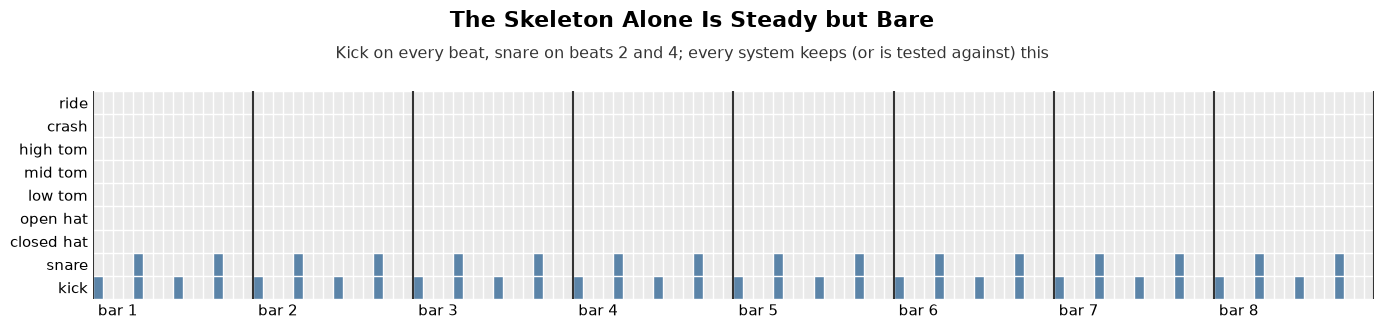

In [2]:
show_loop(skeleton_loop(), "The Skeleton Alone Is Steady but Bare",
          subtitle="Kick on every beat, snare on beats 2 and 4; every system keeps (or is tested against) this")

# 2. The data

We train on the **Groove MIDI Dataset** (GMD; Gillick et al. 2019, "Learning to Groove with Inverse Sequence
Transformations", CC BY 4.0): 1,150 MIDI recordings of ten drummers on an electronic kit, about 13.6 hours. We use
the **official train/validation/test split** and keep only 4/4 grooves (no fills, no other time signatures).

**Representation.** Every hit is snapped to the nearest 16th note using the recording's tempo, and the kit's 22
sounds are grouped into 9 drums (the dataset's own reduced mapping, the same 9 as Drums RNN). A bar becomes a
16 x 9 grid of 0/1: *was this drum hit on this 16th note?* Empty bars at the start and end of each recording
(count-ins) are trimmed.

**What this discards**, and we say so up front:
- **microtiming**: on average a hit sits 17% of a 16th away from its grid line; swing and shuffle (triplet feels)
  are distorted most;
- **velocity**: quiet ghost notes and loud accents become the same hit. This matters for the snare, which averages
  5.2 hits per bar in the data against 2 in our skeleton;
- tempo: all generated loops play at 128 BPM, although most recordings were played at 80-140 BPM.

A longer tour of the data, with more figures and examples, is in [data_analysis/README.md](data_analysis/README.md).

In [3]:
info, bars = load_bars()
summary = (info.groupby("split").agg(recordings=("n_bars", "size"), bars=("n_bars", "sum"))
           .loc[["train", "validation", "test"]])
print(f"{len(info)} recordings (4/4 grooves), {info.n_bars.sum():,} bars after trimming "
      f"({info.trimmed_bars.sum():,} empty edge bars removed, {info.unmappable.sum()} unmappable notes, "
      f"{info.after_last_bar.sum():,} notes after the last complete bar dropped)")
display(summary)

train_bars = np.concatenate([bars[i] for i in info.index[info.split == "train"]])  # (n_bars, 16, 9)
d_gmd = density(train_bars)
per_drum = pd.Series(train_bars.sum(axis=1).mean(axis=0), index=CLASSES).round(2)
print(f"d_GMD = mean decoration hits per bar (channels 2-8, training bars) = {d_gmd:.2f}")
display(per_drum.to_frame("hits per bar").T)

491 recordings (4/4 grooves), 20,597 bars after trimming (1,251 empty edge bars removed, 0 unmappable notes, 2,941 notes after the last complete bar dropped)


,recordings,bars
split,,
train,368,16454
validation,46,2039
test,77,2104


d_GMD = mean decoration hits per bar (channels 2-8, training bars) = 9.96


,kick,snare,closed_hat,open_hat,low_tom,mid_tom,high_tom,crash,ride
hits per bar,3.79,5.18,5.09,0.65,0.45,0.23,0.64,0.28,2.61


**One example before and after quantization.** Orange dots are the moments the drummer actually played; blue
squares are the 16th-note cells they snap to.

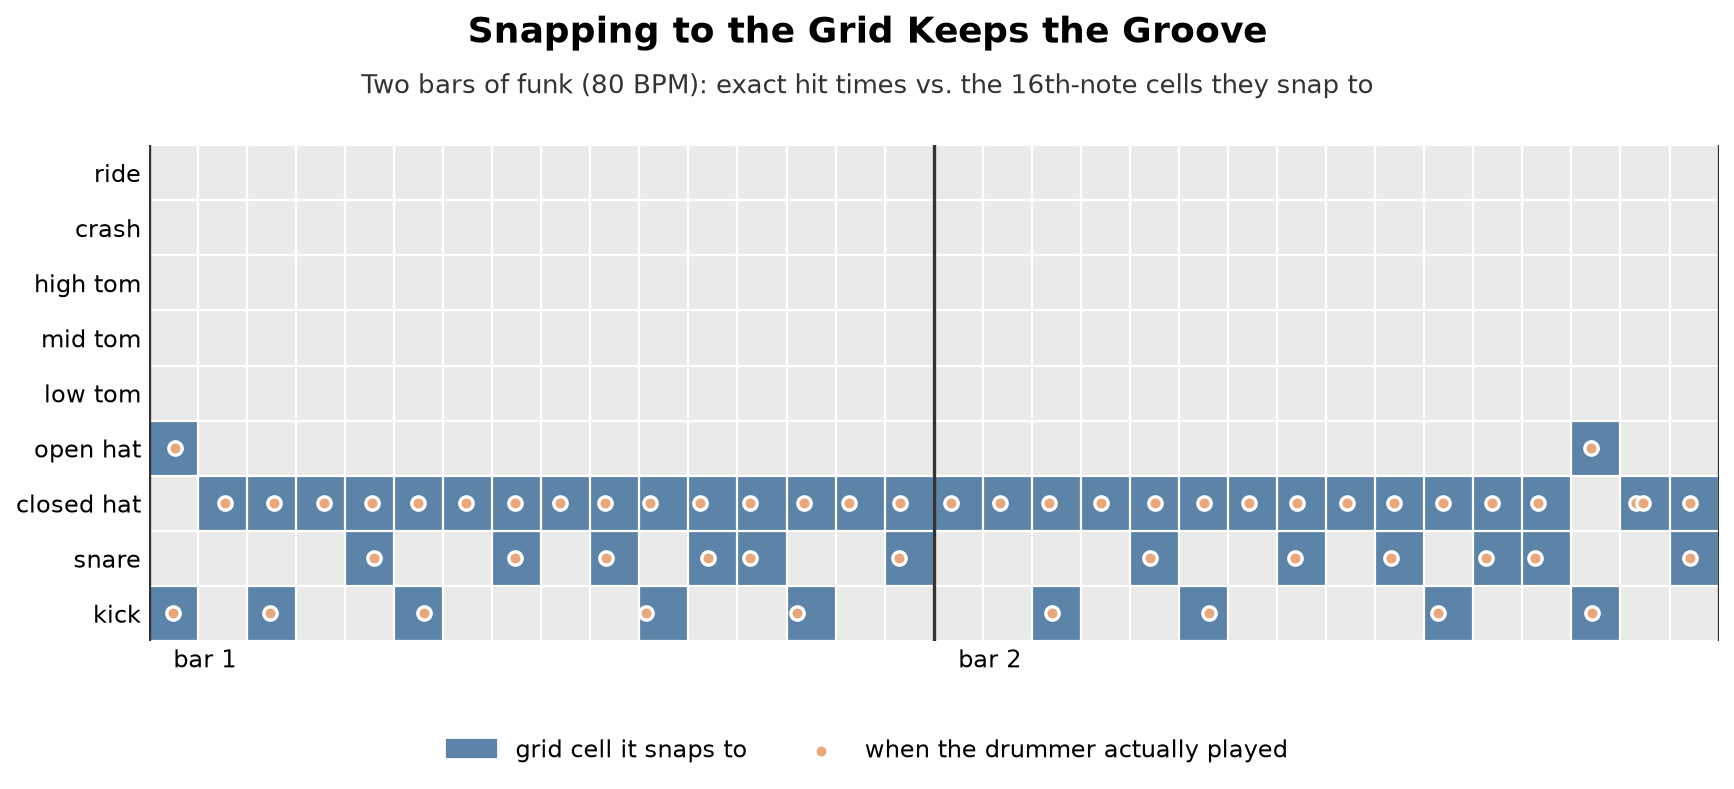

In [4]:
display(Image(filename="data_analysis/figures/quantization.png", width=800))

**Where in the bar drummers play.** The snare half of our skeleton matches the data (snare on 2 and 4 in about 6 of
10 bars), but the kick half does not: drummers mostly play kick on 1 and 3, and only 16% of bars have a kick on all
four beats. Only about 1% of GMD bars match the full skeleton exactly. A model that imitates this data will not
play four on the floor by itself; this is the starting point for section 5.

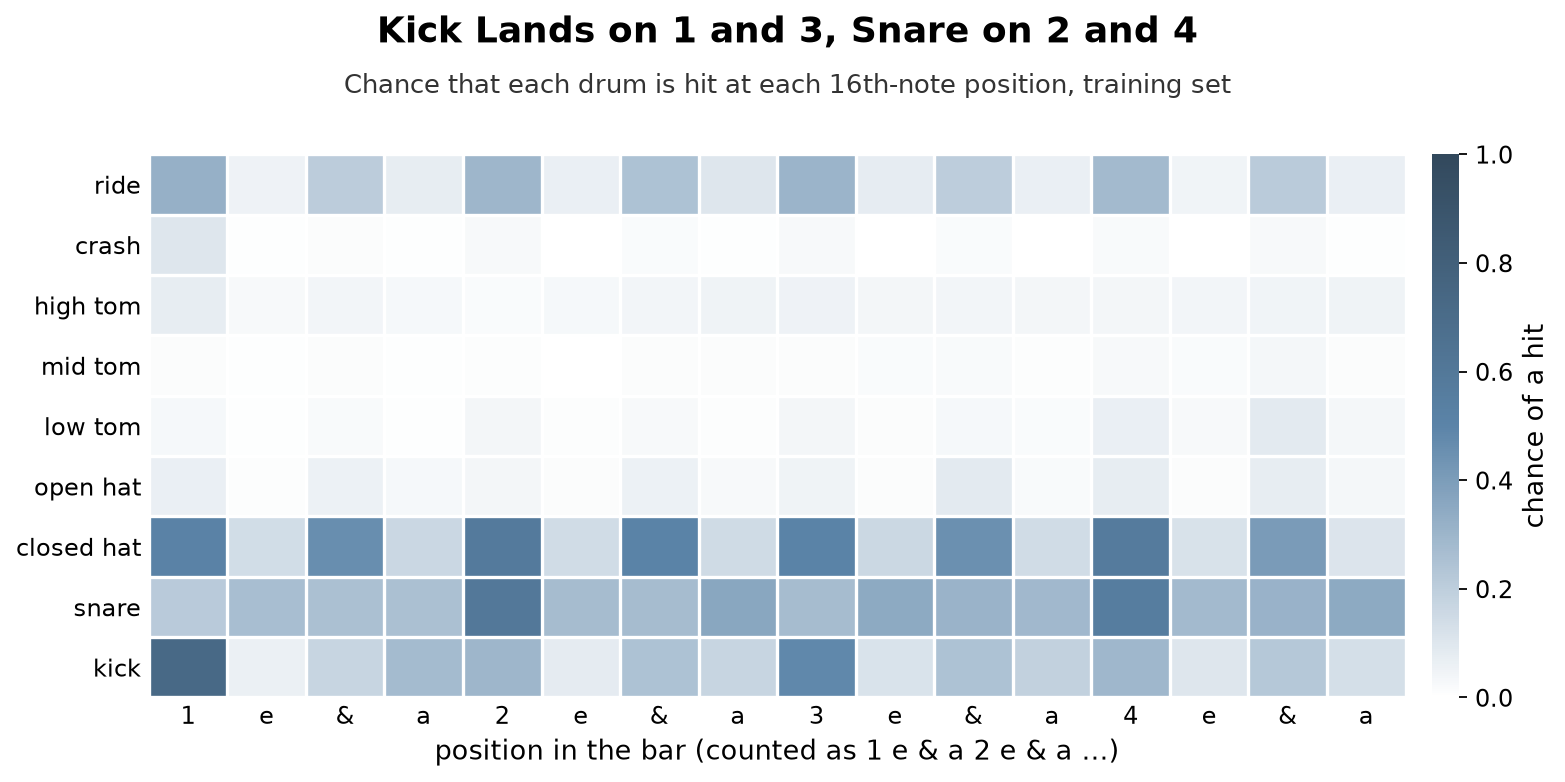

In [5]:
display(Image(filename="data_analysis/figures/where_in_bar.png", width=700))

**Listen to real drumming** after quantization (rock, first training recording of the style with at least 10 bars,
at the drummer's own tempo, rendered with our simple synth at fixed velocity, so it sounds more mechanical than the
original). Note the snare on beat 3: a half-time feel that a fitness class cannot step to.

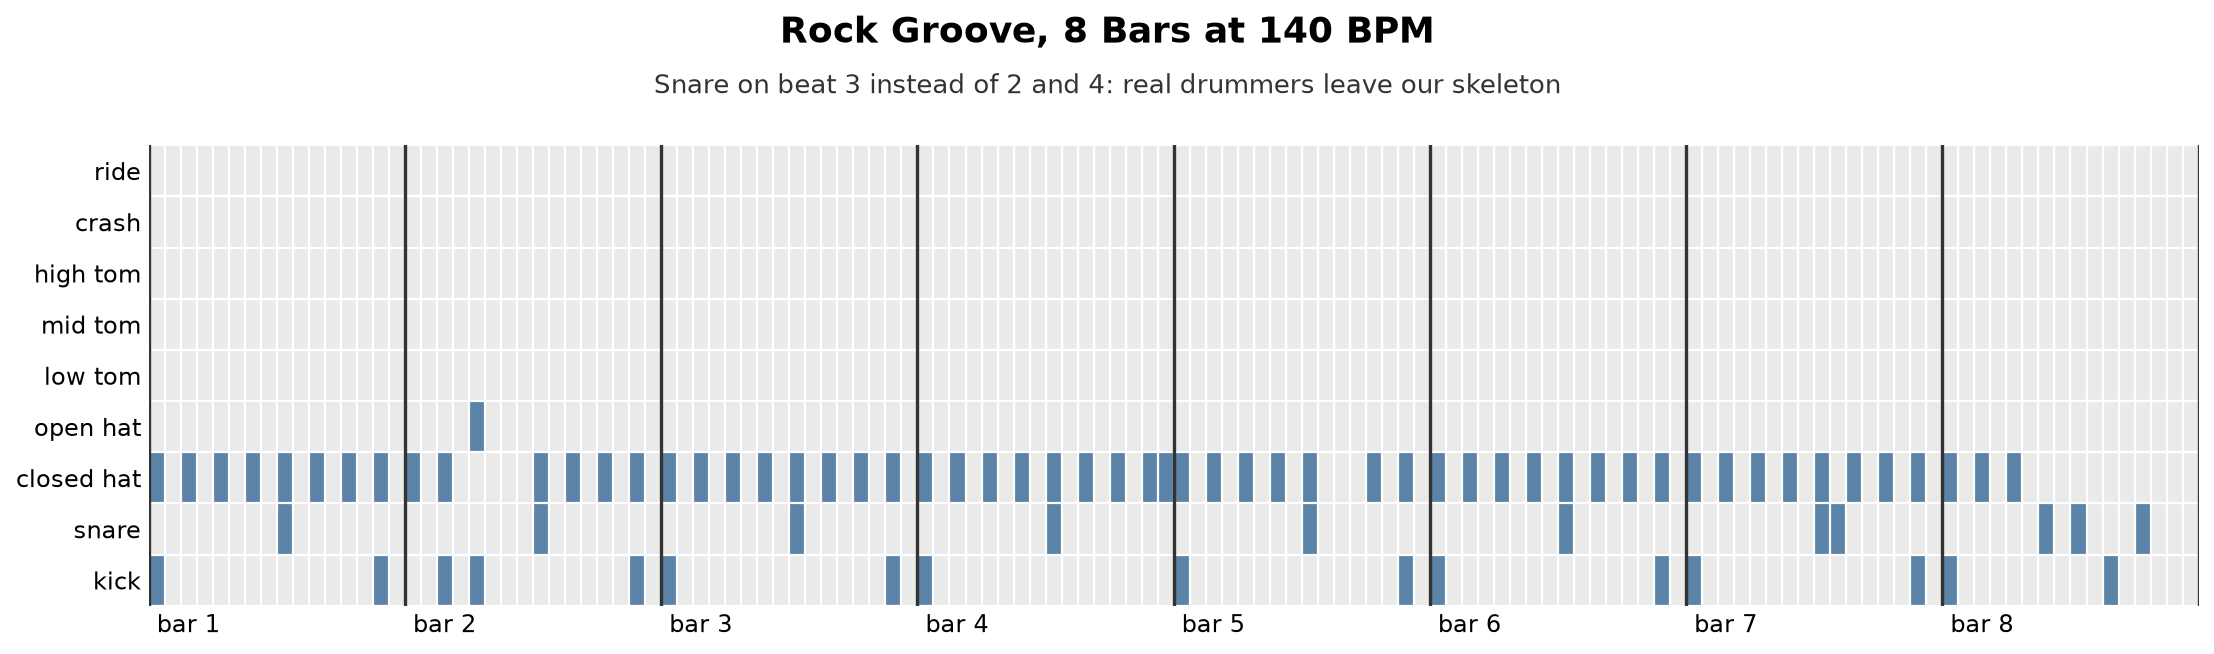

In [6]:
display(Image(filename="data_analysis/figures/example_rock.png", width=900))
play("example_rock", folder=OUTPUT_DIR.parent / "data_analysis" / "audio")

# 3. Rule baseline (A)

System A answers: *what can we do without learning?* On top of the skeleton, every decoration cell gets a
hand-written chance of a hit, depending only on the drum and the position in the bar, sampled independently:

- closed hat on every 8th note (90%), occasionally on the 16ths in between (10%);
- open hat on the "&" of 4, leading into the next bar (30%); a hat is open or closed, not both;
- toms on the last three 16ths of a bar (5% each), crash on beat 1 (25%), ride on the beats (30%).

The probabilities were **set once** so that A's decoration density is close to d_GMD (about 10 hits per bar),
**then frozen**. A was not tuned on anything else, in particular not on bar-to-bar change.

In [7]:
counts = ["1", "e", "&", "a", "2", "e", "&", "a", "3", "e", "&", "a", "4", "e", "&", "a"]
p = pd.DataFrame(rule_probabilities()[:, list(DECORATION_CHANNELS)], index=counts,
                 columns=[CLASSES[c] for c in DECORATION_CHANNELS])
display(p.T.replace(0, "").style.format(lambda v: f"{v:.2f}" if v != "" else ""))

a_loops = np.stack([rule_loop(s) for s in SEEDS])
assert np.array_equal(a_loops, LOOPS["A rules"])  # same seeds give the same loops as the saved results
print(f"A: {density(a_loops):.2f} decoration hits per bar, against d_GMD = {d_gmd:.2f}")

,1,e,&,a,2,e,&,a,3,e,&,a,4,e,&,a
closed_hat,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10
open_hat,,,,,,,,,,,,,,,0.30,
low_tom,,,,,,,,,,,,,,0.05,0.05,0.05
mid_tom,,,,,,,,,,,,,,0.05,0.05,0.05
high_tom,,,,,,,,,,,,,,0.05,0.05,0.05
crash,0.25,,,,,,,,,,,,,,,
ride,0.30,,,,0.30,,,,0.30,,,,0.30,,,


A: 9.88 decoration hits per bar, against d_GMD = 9.96


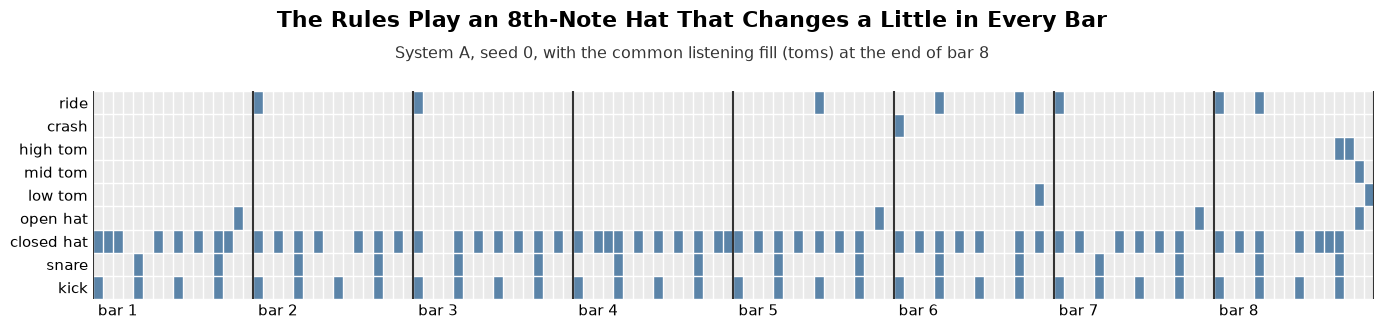

**A, seed 0**

**A, seed 1**

In [8]:
show_loop(add_fill(a_loops[0]), "The Rules Play an 8th-Note Hat That Changes a Little in Every Bar",
          subtitle="System A, seed 0, with the common listening fill (toms) at the end of bar 8")
for s in LISTEN_SEEDS:
    play(f"A_seed{s}", f"A, seed {s}")

# 4. Learned model

**The model predicts the next 16th note of human drumming from everything played so far.** It learns how drummers
continue a groove, not what good fitness music is; the fitness part comes from the constraint in section 5.

```
 previous step (9 drums, 0/1) ─┐
                               ├─► LSTM layers ─► 512 scores ─► softmax ─► sample one drum combination ─┐
 position in bar (one-hot 16) ─┘      (state carried across all 8 bars)                                  │
          ▲                                                                                              │
          └──────────────────────────── fed back as the next input ──────────────────────────────────────┘
```

- **Output.** We compared two output types: *bernoulli* (an independent hit chance per drum) and *categorical*
  (one choice among all 2^9 = 512 drum combinations per step, as Drums RNN). The categorical output can learn which
  drums go together and which exclude each other (an open and a closed hat); drummers use only 145 of the 512.
- **Loss.** Both are trained on the negative log-likelihood of the real next step, in nats per step, so they
  compare directly. This proper scoring rule keeps probabilities calibrated, so sampled loops get a realistic
  density without any tuning.
- **Sizes.** 2x128, 2x256 and 3x256 (the Drums RNN size), each output type x size trained once (seed 0); the lowest
  validation loss wins.
- **Training.** 8-bar windows (128 steps, the same length as the generated loops), stride 2 bars: 7,212 training
  windows. Teacher forcing, Adam (learning rate 0.001), batch 64, gradient clipping 3, early stopping on the
  validation loss (patience 15), deterministic GPU kernels.

| | Drums RNN (`drum_kit`) | Ours |
|---|---|---|
| Drums, time step | 9 drums, 16th notes | same |
| Output | one of 512 combinations | both that and 9 independent drums, compared |
| Inputs | previous combination (one-hot 512), 6-bit position counter | previous drums (9, same information), one-hot position (16) |
| Network | 3 x 256 LSTM, attention over 32 steps | 2x128 to 3x256 compared; no attention |
| Training | dropout 0.5, lr 0.001, batch 128, clipping 3 | dropout 0.2-0.5, lr 0.001, batch 64, clipping 3 |

In [9]:
selection = pd.read_csv(RESULTS / "model_selection.csv")
display(selection.style.format({"validation loss": "{:.3f}", "parameters": "{:,}"}).hide(axis="index"))

output,size,parameters,best epoch,validation loss
categorical,Drums RNN 3x256,"1,474,048",63,1.430
categorical,medium 2x256,"947,712",44,1.448
categorical,small 2x128,"277,504",57,1.475
bernoulli,medium 2x256,"818,441",31,1.500
bernoulli,small 2x128,"212,617",46,1.516
bernoulli,Drums RNN 3x256,"1,344,777",35,1.523


The **categorical 3x256** model (the Drums RNN configuration) has the lowest validation loss, and every categorical
model beats every bernoulli model: predicting the drums of a step jointly is better than predicting them
independently. This configuration was then trained with **5 seeds** (0-4) to show how much the results depend on
the training run; B, C and D are reported as the mean and range over those 5 models.

seed,best epoch,validation loss
0,63,1.430
1,43,1.432
2,42,1.423
3,31,1.416
4,52,1.423


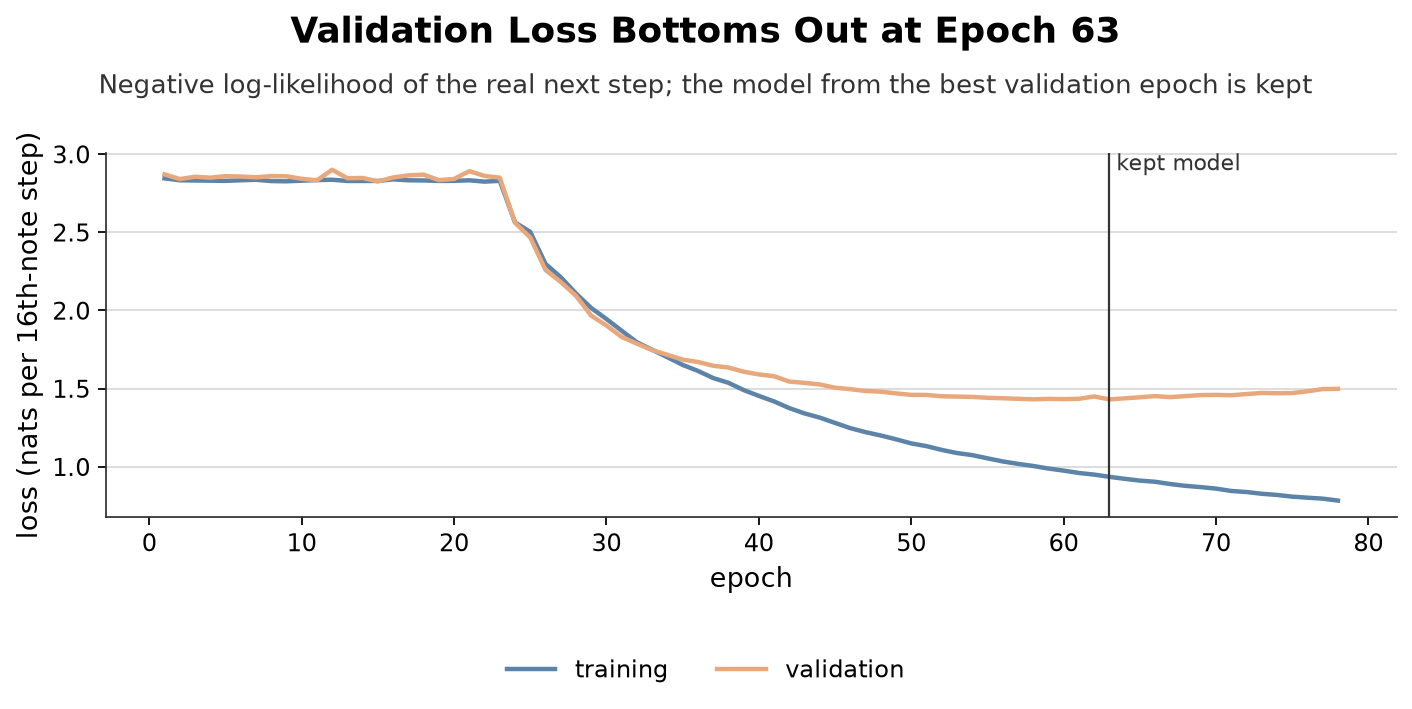

In [10]:
training = pd.read_csv(RESULTS / "training.csv")
display(training[["seed", "best epoch", "validation loss"]].style.format({"validation loss": "{:.3f}"})
        .hide(axis="index"))
display(Image(filename=str(RESULTS / "loss_curve.png"), width=750))

The validation loss is about 1.42-1.43 nats per step across seeds, so the training run matters little for the
loss. (Test loss is reported once, at the end of section 6.) Validation loss measures how well the model predicts
unseen human drumming, not musical quality.

**Generation.** Start from an all-zero input, sample one combination per step at temperature 1.0, feed it back, and
carry the LSTM state across all 8 bars (never reset at bar lines). In **free mode (B)** the model chooses every drum.
The animation below shows the real model (training seed 0, listening seed 0) writing a loop one 16th note at a time,
first free, then constrained.

![How the model writes a loop](output/animation/generation.gif)

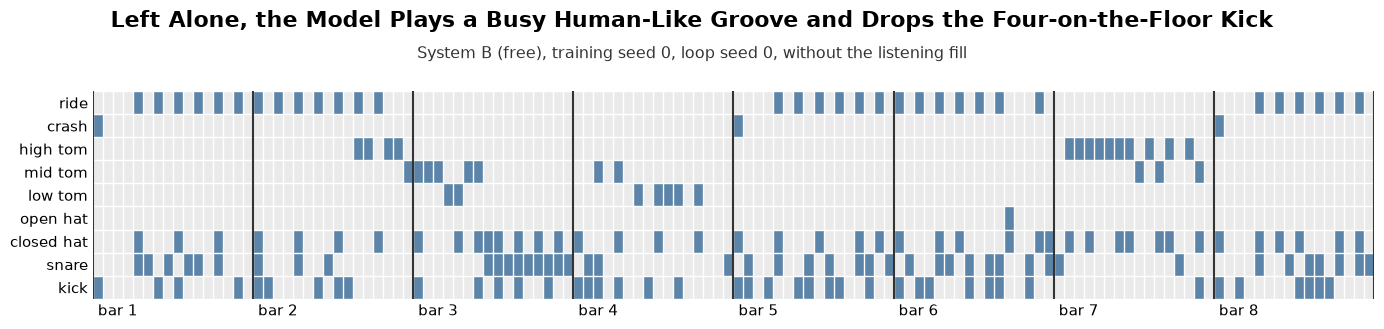

**B, seed 0 (with the listening fill)**

**B, seed 1 (with the listening fill)**

In [11]:
show_loop(LOOPS["B free|0"][0], "Left Alone, the Model Plays a Busy Human-Like Groove and Drops the Four-on-the-Floor Kick",
          subtitle="System B (free), training seed 0, loop seed 0, without the listening fill")
for s in LISTEN_SEEDS:
    play(f"B_seed{s}", f"B, seed {s} (with the listening fill)")

# 5. Adding constraints (C)

The free model sounds like real drumming, and that is the problem: real drummers in this dataset mostly do not play
four on the floor (section 2), so neither does B. Its kick drifts to 1 and 3, the snare picks up ghost notes, and a
fitness class loses the beat it steps to.

**Instead of asking the model to control decisions that must be reliable, we constrain them.** At every step:

1. the kick and snare are set to the skeleton's values, not sampled;
2. the model samples only among the drum combinations whose kick and snare match the skeleton (for the categorical
   output: 128 of the 512 combinations, renormalised). This is the exact conditional distribution of the
   decoration given the skeleton, under the model;
3. the forced values are fed back as the next input, so the model "hears" the four-on-the-floor kick and plays
   around it.

The model is unchanged; only the sampling step is. Kick and snare are now guaranteed by construction, and all the
model's choices go into the decoration.

**Check: the constraint holds for every loop**, and the saved loops are reproducible. If the trained checkpoints are
present (`python -m src.train` recreates them), we regenerate one loop live and compare it with the saved one.

In [12]:
skel = skeleton_loop()[:, :2]
for name in ("C constrained", "D fine-tuned"):
    loops = np.concatenate([LOOPS[f"{name}|{ts}"] for ts in range(5)])
    print(f"{name}: kick/snare equal the skeleton in {np.mean([np.array_equal(l[:, :2], skel) for l in loops]):.0%}"
          f" of {len(loops)} loops")

if (CHECKPOINT_DIR / "lstm_base_seed0.pt").exists():
    from src.train import load_model
    live = lstm_loop(load_model("base", 0), seed=0, constrained=True).loop
    print("live regeneration matches the saved loop:", np.array_equal(live, LOOPS["C constrained|0"][0]))
else:
    print("no checkpoints found; skipping the live regeneration")

C constrained: kick/snare equal the skeleton in 100% of 150 loops
D fine-tuned: kick/snare equal the skeleton in 100% of 150 loops


live regeneration matches the saved loop: True


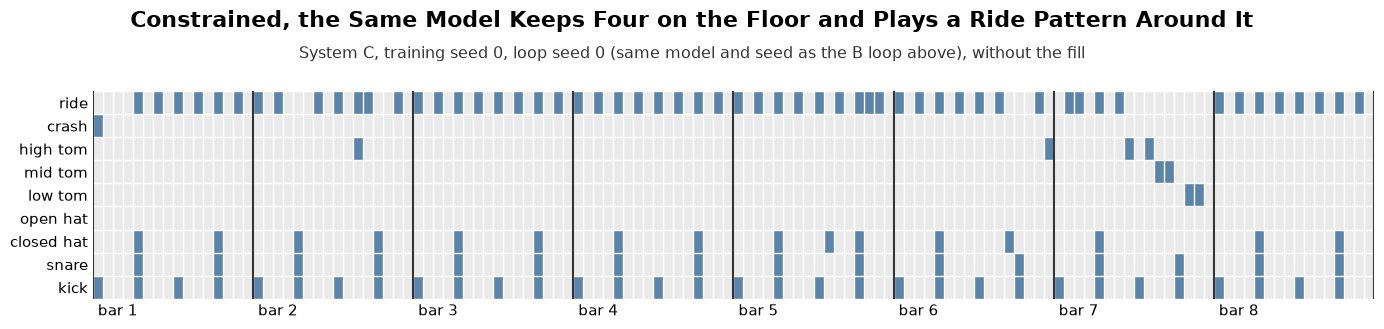

**C, seed 0 (with the listening fill)**

**C, seed 1 (with the listening fill)**

In [13]:
show_loop(LOOPS["C constrained|0"][0], "Constrained, the Same Model Keeps Four on the Floor and Plays a Ride Pattern Around It",
          subtitle="System C, training seed 0, loop seed 0 (same model and seed as the B loop above), without the fill")
for s in LISTEN_SEEDS:
    play(f"C_seed{s}", f"C, seed {s} (with the listening fill)")

**System D** asks whether training on data that matches our intent helps. Each trained model continues training
(learning rate 1e-4, early stopping) on the windows in which every bar has a kick on all four beats (713 training,
185 validation windows; data the model has already seen, so no test data leaks), then generates as C.

In [14]:
for s in LISTEN_SEEDS:
    play(f"D_seed{s}", f"D, seed {s} (with the listening fill)")

**D, seed 0 (with the listening fill)**

**D, seed 1 (with the listening fill)**

# 6. Experiment

**Metrics** (all on the full 8 bars of each loop, 30 loops per system):

| Metric | Channels | Question |
|---|---|---|
| Skeleton accuracy | kick, snare | Share of kick/snare cells that match the skeleton (missing *and* extra hits count). An empty kick/snare track still scores about 81% |
| Exact-bar rate | kick, snare | Share of bars whose kick and snare match the skeleton exactly: the stricter pulse measure |
| Diversity | decoration | Mean pairwise Hamming distance between the 30 loops: does the system generate varied rhythms? |
| Density | decoration | Decoration hits per bar: is a difference in diversity just more notes? |
| Bar-to-bar change | decoration | Share of decoration cells that change between consecutive bars: 0 for a static loop |
| Repeat rate | decoration | Share of consecutive bars with exactly the same decoration: does it repeat, then vary? |

The **GMD reference** row scores 30 non-overlapping 8-bar windows of real drumming from the test split (fixed
seed). It is a reference for what human drumming looks like on these measures, not a competitor.

**Expectations, stated before the results** (from the plan):
- B breaks the pulse a noticeable share of the time, with skeleton accuracy roughly like real drumming (about 72%).
- C keeps the pulse by construction; whether it is more varied than A is decided by the table and listening.
- We first expected A to change too much from bar to bar (like random hits, about 13%). This was wrong: A changes
  5.8% per bar, close to drummers, because its probabilities are near 0 or 0.9. Revised before B and C existed:
  A almost never repeats a bar exactly, and C repeats bars more often, closer to the human 25%.

In [15]:
summary = pd.read_csv(RESULTS / "results_summary.csv", header=[0, 1], index_col=0)
rows = ["GMD reference", "A rules", "B free", "C constrained", "D fine-tuned"]
metrics = summary.columns.get_level_values(0).unique()


def cell(system: str, metric: str) -> str:
    lo, mid, hi = (summary.loc[system, (metric, k)] for k in ("min", "mean", "max"))
    fmt = "{:.1f}" if metric == "density" else "{:.3f}"
    return fmt.format(mid) + (f" [{fmt.format(lo)}-{fmt.format(hi)}]" if hi > lo else "")


table = pd.DataFrame({m: [cell(r, m) for r in rows] for m in metrics}, index=rows)
display(Markdown("B-D: mean over the 5 trained models [min-max]. A and the reference do not depend on training."))
display(table)

B-D: mean over the 5 trained models [min-max]. A and the reference do not depend on training.

,skeleton accuracy,exact-bar rate,diversity,density,bar-to-bar change,repeat rate
GMD reference,0.741,0.004,0.106,9.6,0.045,0.252
A rules,1.000,1.000,0.059,9.9,0.058,0.000
B free,0.723 [0.697-0.757],0.011 [0.000-0.017],0.125 [0.116-0.133],10.3 [9.7-10.8],0.055 [0.046-0.069],0.093 [0.052-0.143]
C constrained,1.000,1.000,0.125 [0.113-0.133],9.8 [9.1-10.2],0.047 [0.040-0.057],0.079 [0.052-0.129]
D fine-tuned,1.000,1.000,0.138 [0.123-0.151],11.3 [10.1-12.6],0.057 [0.048-0.065],0.059 [0.024-0.086]


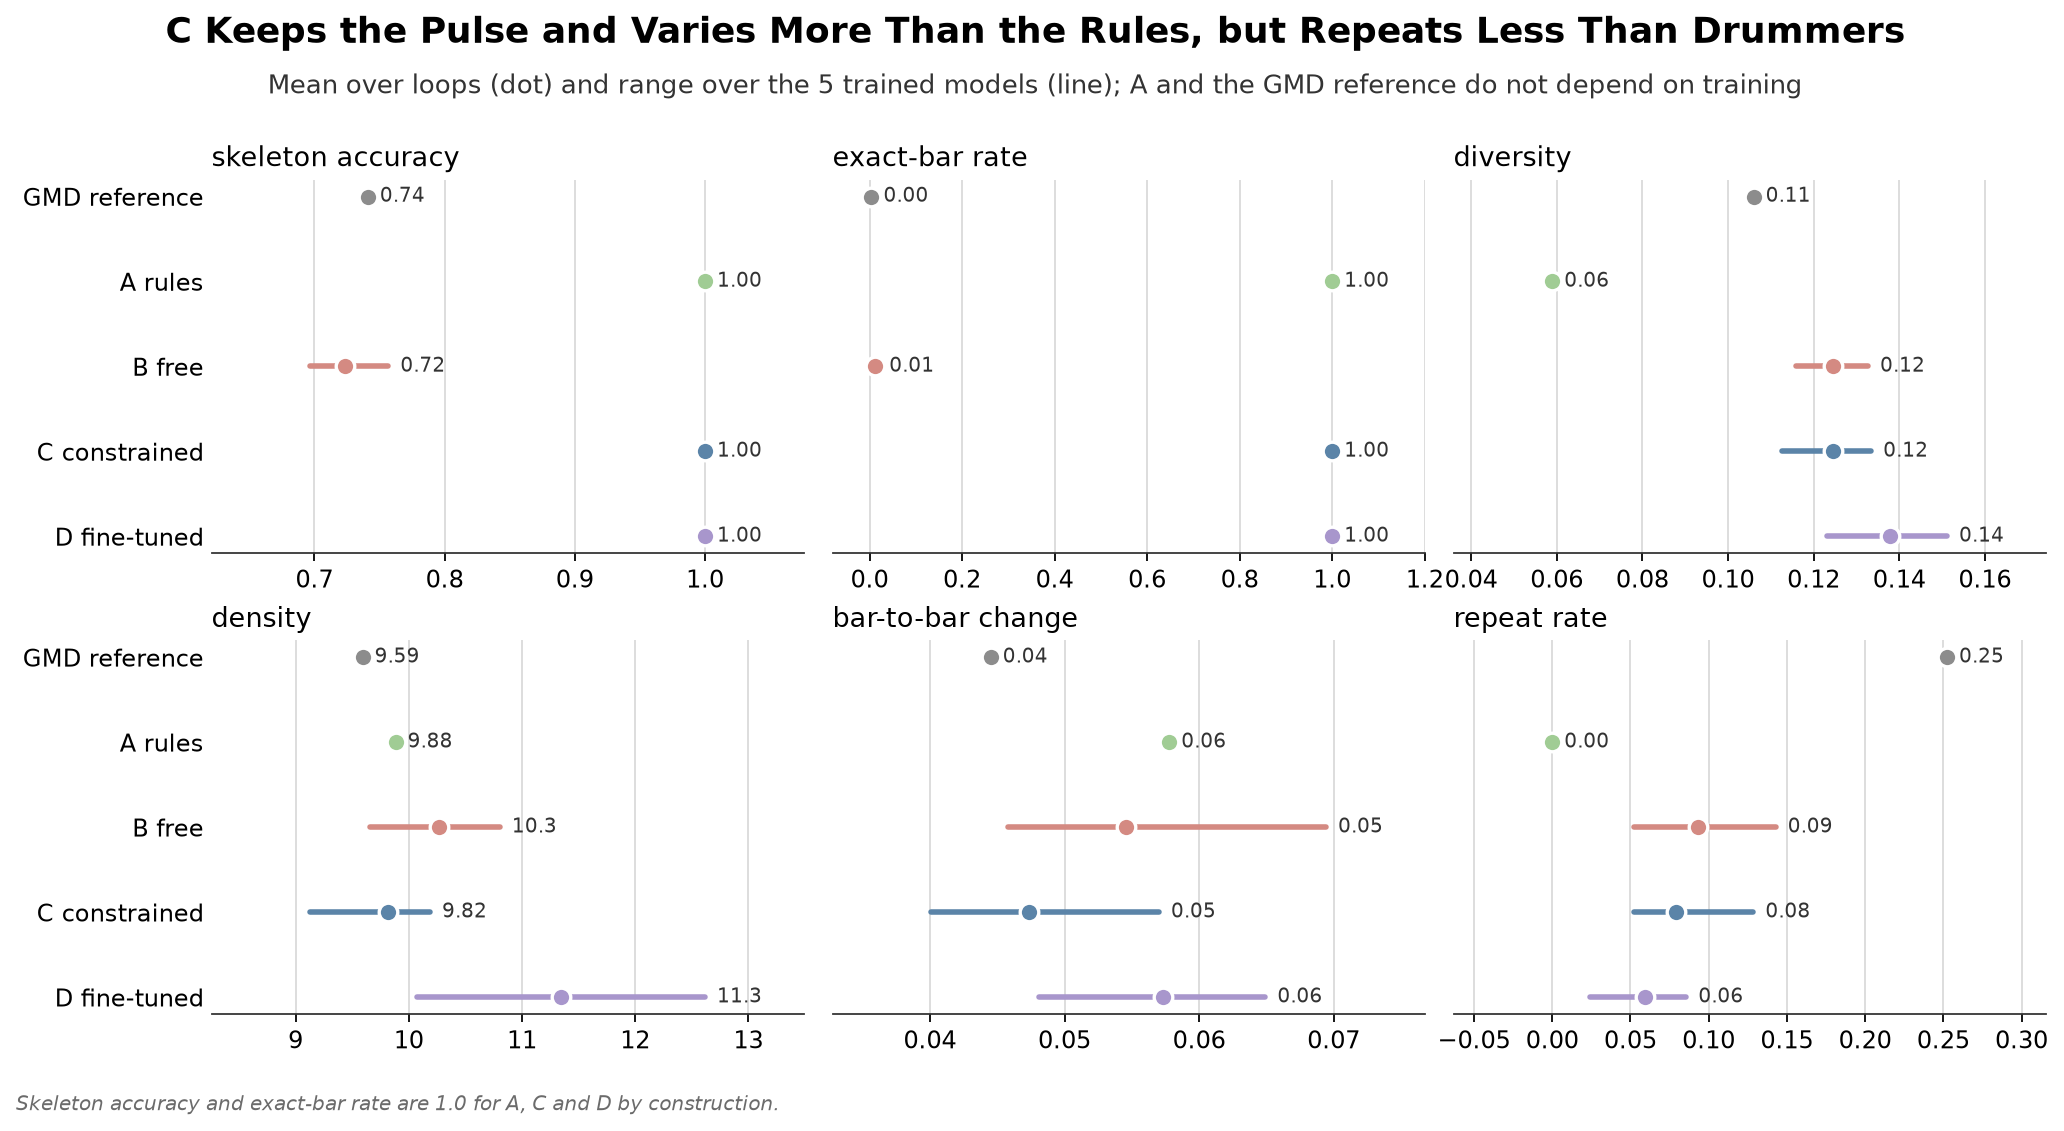

In [16]:
display(Image(filename=str(RESULTS / "results.png"), width=950))

**Steady (B vs C).** B's exact-bar rate is about **1%** (0-1.7% over the five models): the free model almost never
plays a bar a fitness class could rely on. Its skeleton accuracy (72%) is close to real drumming (74%), so this is
not a broken model; it imitates drummers who do not play four on the floor. C and D are at 100% by construction.
Even after fine-tuning on four-on-the-floor bars, the free version of D reaches only **5.5%** exact bars
(skeleton accuracy 78%): matching data alone does not keep the pulse. The constraint is needed.

**Alive (A vs C).** At almost the same density (9.8 vs 9.9 decoration hits per bar):
- **Diversity:** C's loops differ from each other about **twice as much** as A's (0.125 vs 0.059), and more than
  the real-drumming windows (0.106). The constraint does not reduce variety: C and B have the same diversity.
- **Bar-to-bar change:** C changes 4.7% of decoration cells per bar, close to real drumming (4.5%); A changes 5.8%.
- **Repeat rate:** C sometimes repeats a bar exactly (**8%**, 5-13% over models); A never does (0%). But drummers
  repeat far more (**25%**). C moves in the right direction, but falls well short of the human "repeat, then vary".

So, on the numbers, learning adds variation that the rules lack, and changes over time somewhat more like a
drummer, but it does not reach the drummers' repetition. The listening test decides whether this is heard
(below, still to be done).

**C vs D.** Fine-tuning makes the decoration busier (11.3 hits per bar) and more diverse (0.138), but it repeats
bars even less (6%): it moves away from the human reference on density and repetition.

## Follow-up analyses

**1. Copying.** Is the model generating, or replaying memorised material? For each generated bar we look for an
identical bar (decoration only) in the training data, and for each loop an identical 8-bar training window.

In [17]:
copying = pd.read_csv(RESULTS / "copying.csv", index_col=0)
display(copying.style.format("{:.3f}"))

,bars found in training,distance to nearest training bar,loops copied from training
system,,,
GMD reference,0.388,0.015,0.100
A rules,0.071,0.020,0.000
B free,0.405,0.016,0.013
C constrained,0.383,0.015,0.000
D fine-tuned,0.332,0.019,0.000
D free,0.347,0.017,0.000


About 38% of C's bars appear somewhere in the training bars, the same share as for real drumming from the
*test* split (39%): common bars (an 8th-note hat, for example) are common for drummers too. No C loop copies a
whole training window. The model recombines familiar bars into new loops; it does not replay recordings.
(10% of the reference loops occur exactly in the training windows: some simple grooves recur across recordings.)

**2. Phrase position.** Decoration change at each bar boundary. The model only sees the position within the bar,
so a peak at 7-8 would mean it learned phrasing from the data on its own.

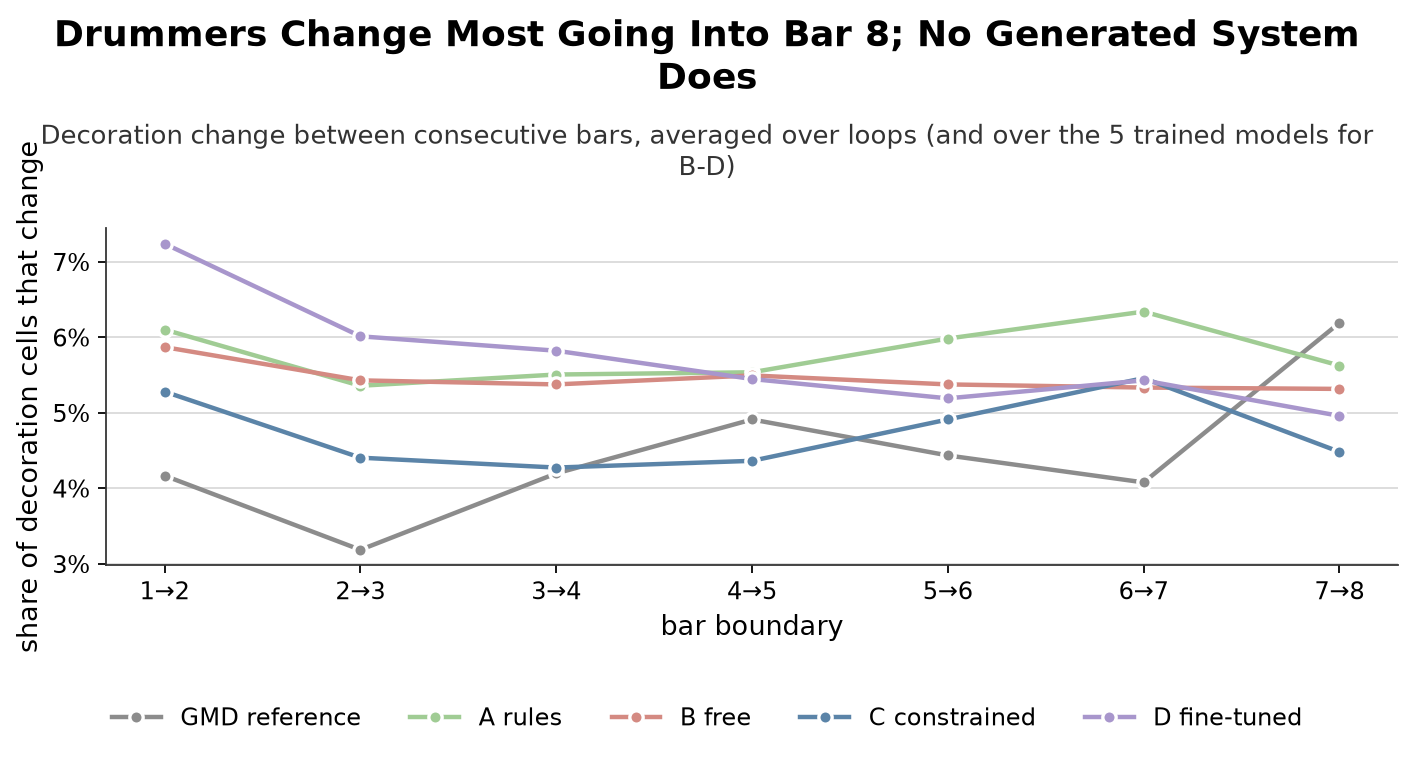

In [18]:
display(Image(filename=str(RESULTS / "phrase_position.png"), width=800))

Real drummers change most going into bar 8 (6.2% against about 4% elsewhere). **No generated system shows this
peak**: C is flat (4.3-5.5%), and A is flat by design. With only position-in-bar as input and no notion of bar
number, the model has no reason to know where a phrase ends. This is one reason C does not sound like a drummer
playing phrases; it would need a bar counter or phrase input (future work).

**3. Cost of the constraint.** In C, how much probability did the model itself give to the kick/snare values that
the skeleton then forced, per position in the bar?

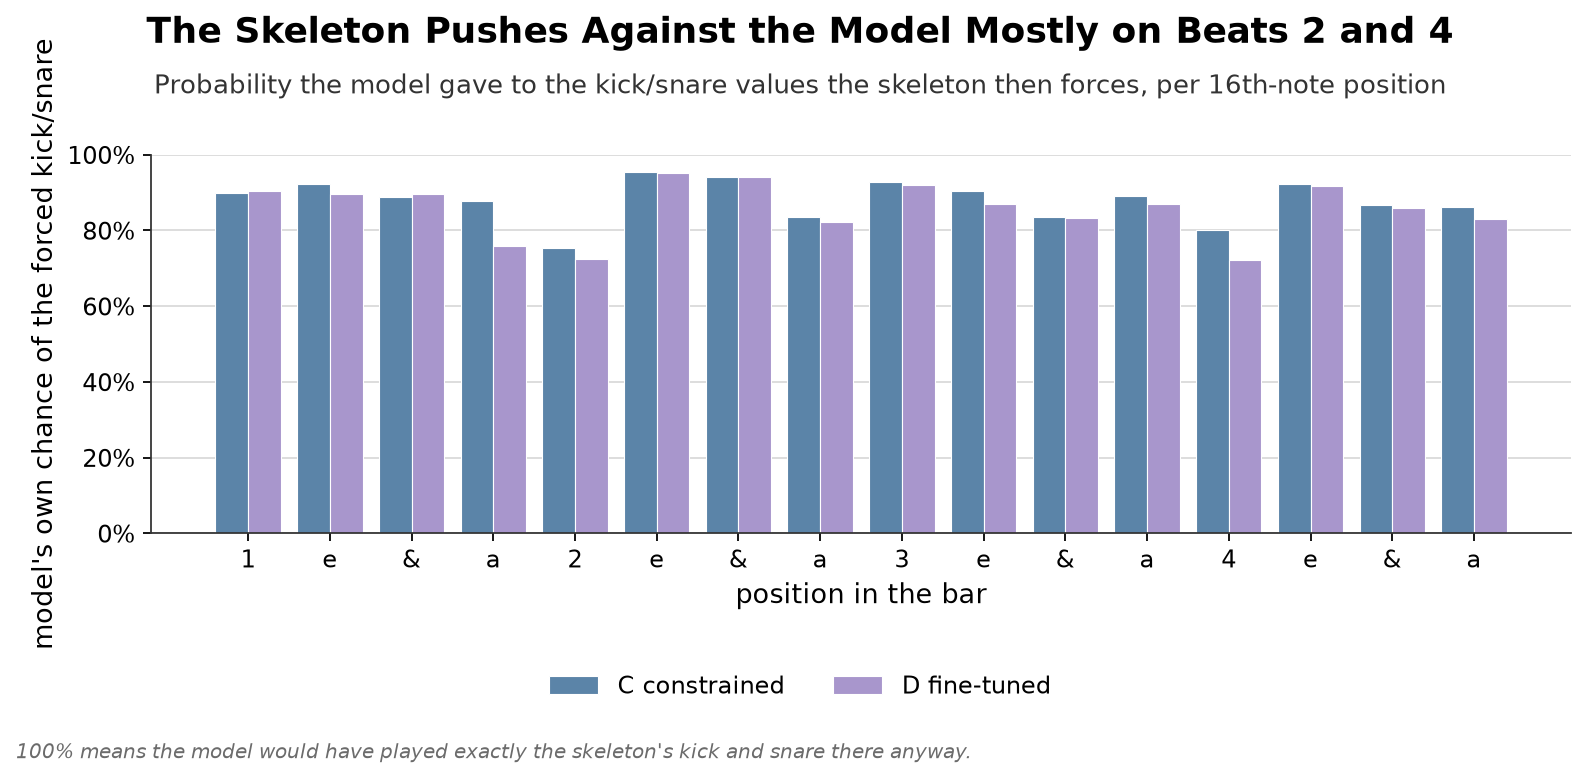

mean chance of the forced kick/snare: {'C constrained': 0.88, 'D fine-tuned': 0.86}


In [19]:
display(Image(filename=str(RESULTS / "constraint_cost.png"), width=850))
cost = pd.read_csv(RESULTS / "constraint_cost.csv", index_col=0)
print("mean chance of the forced kick/snare:", cost.mean().round(2).to_dict())

On most positions the model already agrees with the skeleton (about 90%), because once it hears four on the floor
fed back it tends to continue it. The constraint pushes hardest on **beats 2 and 4** (about 75-80%), where the
skeleton demands kick *and* snare together, a combination rock drummers rarely play. The cost is modest: the
model is not forced into something it finds implausible at most steps, which fits the decoration staying close to
B's (same diversity, similar density).

**4. How B breaks the pulse.** B's differences from the skeleton, per bar, by type, against real drumming.

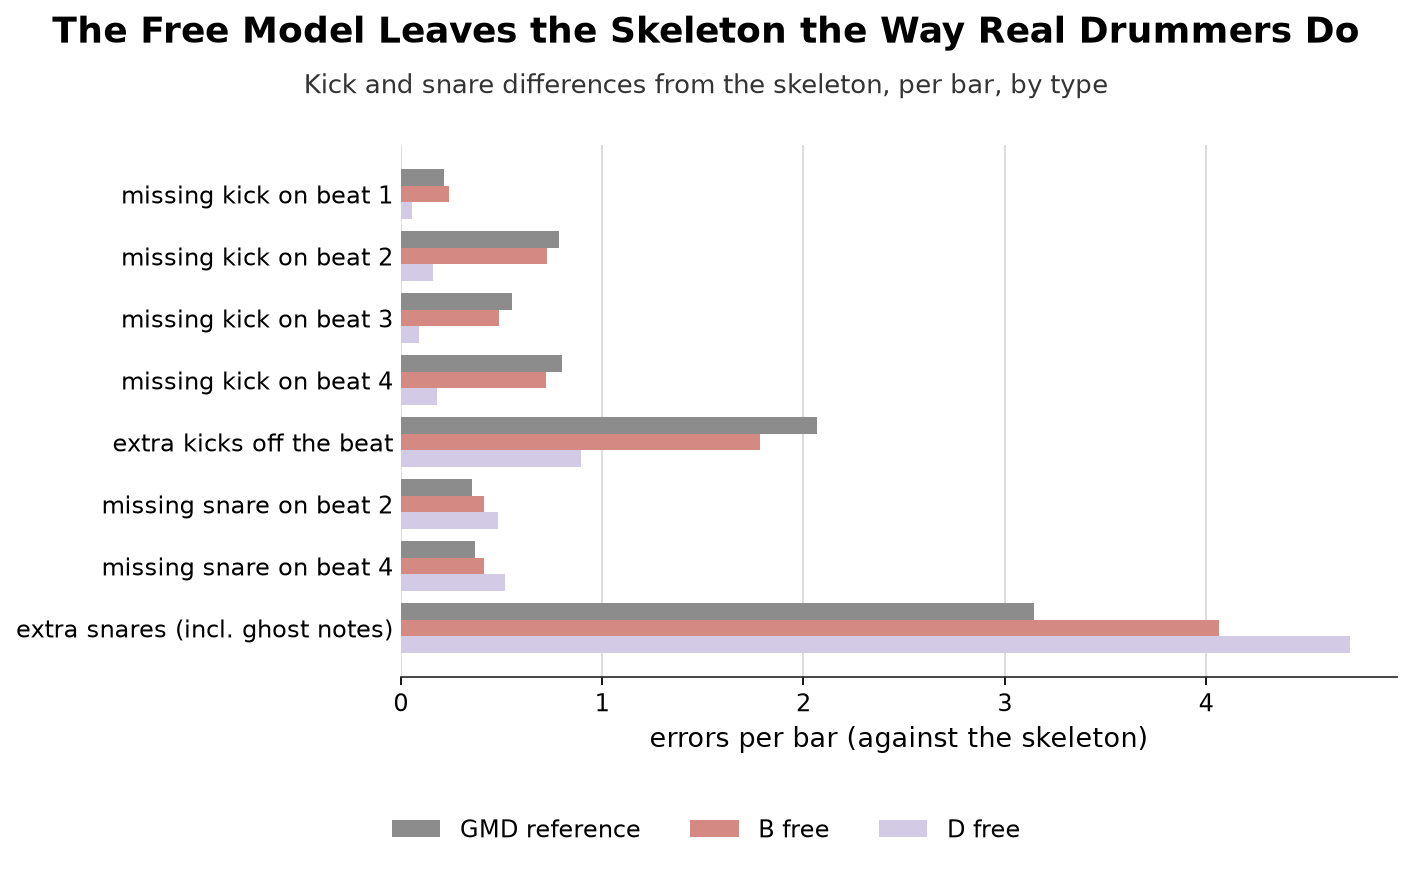

,GMD reference,B free,D free
missing kick on beat 1,0.21,0.24,0.06
missing kick on beat 2,0.79,0.73,0.16
missing kick on beat 3,0.55,0.49,0.09
missing kick on beat 4,0.80,0.72,0.18
extra kicks off the beat,2.07,1.79,0.89
missing snare on beat 2,0.35,0.41,0.48
missing snare on beat 4,0.37,0.41,0.52
extra snares (incl. ghost notes),3.15,4.06,4.71


In [20]:
display(Image(filename=str(RESULTS / "pulse_errors.png"), width=800))
display(pd.read_csv(RESULTS / "pulse_errors.csv", index_col=0).round(2))

B misses the kick on beats 2 and 4 in about 7 of 10 bars and adds kicks off the beat, almost exactly as the real
drummers do. It plays a musically sensible rock beat, wrong only for fitness. It plays more extra snares than the
drummers (4.1 vs 3.1 per bar): ghost notes, which count as full hits without velocity. Fine-tuned D (free) plays
the four kicks much more often, but still misses the snare on 2 and 4 in about half the bars.

# 7. Reflection

TODO